# **logistic regression from scratch**

# Régression Logistique : Théorie, Implémentation *from scratch*, Visualisations et Évaluation

Ce notebook présente une implémentation complète de la régression logistique :

- Exploration du dataset (visualisations)
- Formulation mathématique du modèle
- Fonction de coût (log-loss)
- Dérivation du gradient
- Implémentation complète en NumPy (*from scratch*)
- Descente de gradient (gradient descent)
- Courbe de convergence
- Prédictions et métriques d’évaluation
- Courbe ROC & AUC
- Comparaison avec `sklearn.LogisticRegression`

L’objectif est de comprendre **le math derrière** la régression logistique et de montrer son fonctionnement pratique.


link for our dataset :
https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data?resource=download

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Chargement et préparation du dataset

Nous utilisons le dataset *Breast Cancer Wisconsin Diagnostic* :  
- 0 = tumeur bénigne  
- 1 = tumeur maligne  

Chaque observation possède 30 *features* décrivant la forme des cellules.


In [4]:

from sklearn.model_selection import train_test_split

# Charger le dataset
data = pd.read_csv("/content/data.csv")

# Supprimer colonnes inutiles
data.drop(['Unnamed: 32', 'id'], axis=1, inplace=True)

# Encoder la cible : M -> 1, B -> 0
data['diagnosis'] = [1 if d == "M" else 0 for d in data['diagnosis']]

# Séparer features et cible
y = data['diagnosis'].values           # shape (m,)
x_data = data.drop(['diagnosis'], axis=1)  # shape (m, n)

print("Shape x_data :", x_data.shape)
print("Shape y      :", y.shape)

Shape x_data : (569, 30)
Shape y      : (569,)


In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

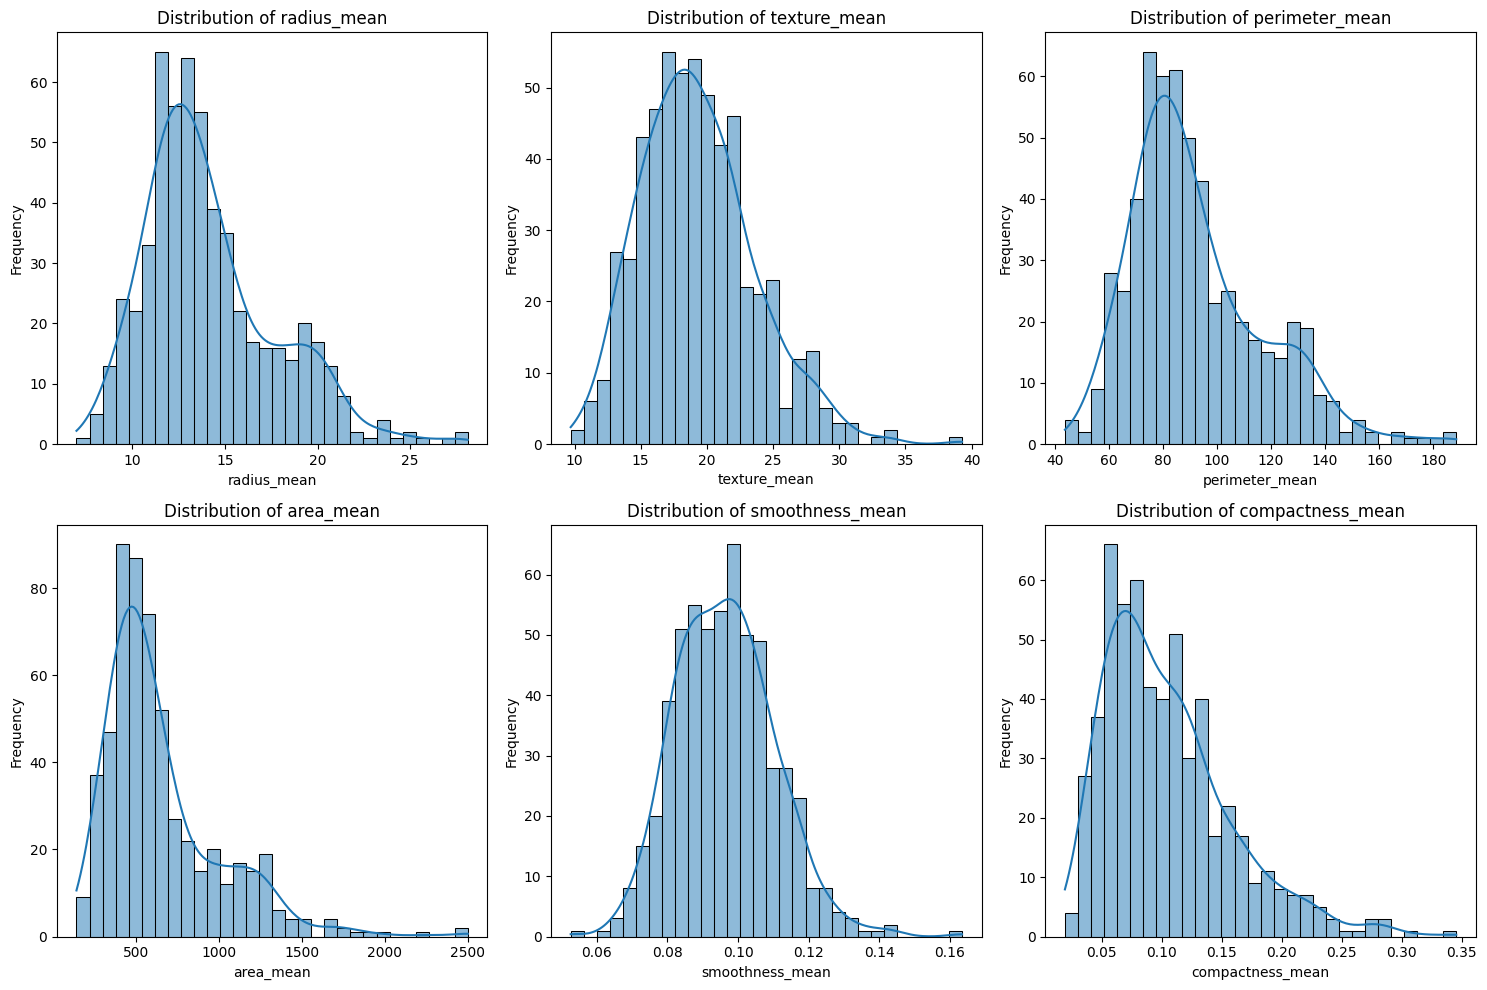

In [6]:

plt.figure(figsize=(15, 10))

# Select a few key features for histograms
features_to_plot = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean']

for i, feature in enumerate(features_to_plot):
    plt.subplot(2, 3, i + 1) # 2 rows, 3 columns
    sns.histplot(x_data[feature], kde=True, bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

## 2. Exploration des classes

Avant de construire un modèle, il est essentiel de vérifier l'équilibre des classes.

La variable cible prend deux valeurs :

- **0** : Bénin  
- **1** : Malin  

Voici la répartition :


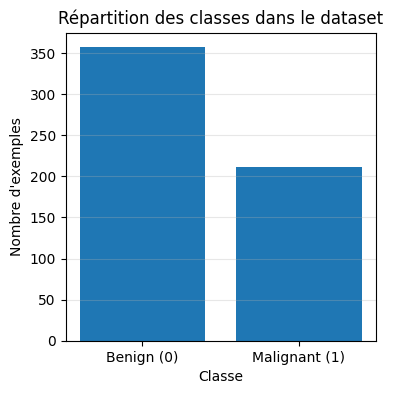

Nombre de benign (0)   : 357
Nombre de malignant (1): 212


In [7]:
class_counts = data['diagnosis'].value_counts().sort_index()  # 0 puis 1

plt.figure(figsize=(4,4))
plt.bar([0, 1], class_counts.values)
plt.xticks([0, 1], ['Benign (0)', 'Malignant (1)'])
plt.xlabel("Classe")
plt.ylabel("Nombre d'exemples")
plt.title("Répartition des classes dans le dataset")
plt.grid(axis='y', alpha=0.3)
plt.show()

print("Nombre de benign (0)   :", class_counts[0])
print("Nombre de malignant (1):", class_counts[1])


## Distribution de quelques caractéristiques

Nous visualisons la distribution de deux features importantes :

- `radius_mean`  
- `texture_mean`

Ces histogrammes montrent comment les deux classes se séparent.


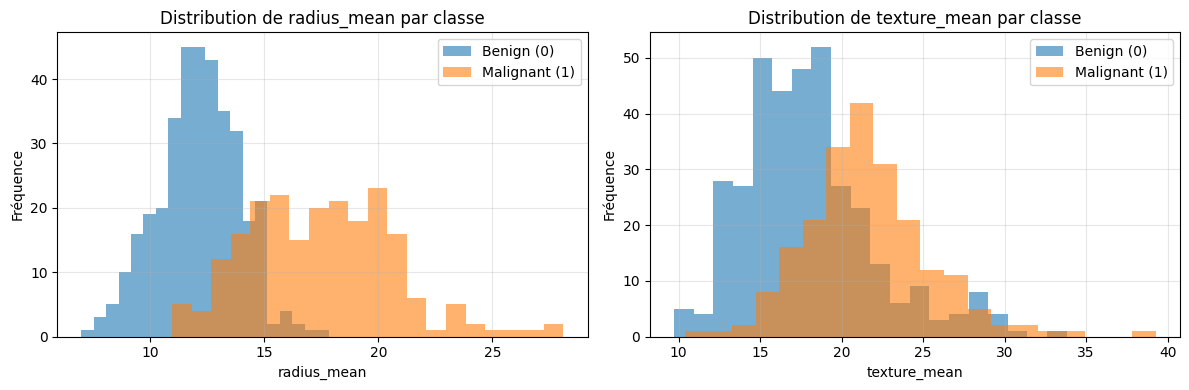

In [8]:
feature1 = "radius_mean"
feature2 = "texture_mean"

plt.figure(figsize=(12,4))

# Feature 1
plt.subplot(1, 2, 1)
plt.hist(data[data['diagnosis'] == 0][feature1], bins=20, alpha=0.6, label='Benign (0)')
plt.hist(data[data['diagnosis'] == 1][feature1], bins=20, alpha=0.6, label='Malignant (1)')
plt.xlabel(feature1)
plt.ylabel("Fréquence")
plt.title(f"Distribution de {feature1} par classe")
plt.legend()
plt.grid(alpha=0.3)

# Feature 2
plt.subplot(1, 2, 2)
plt.hist(data[data['diagnosis'] == 0][feature2], bins=20, alpha=0.6, label='Benign (0)')
plt.hist(data[data['diagnosis'] == 1][feature2], bins=20, alpha=0.6, label='Malignant (1)')
plt.xlabel(feature2)
plt.ylabel("Fréquence")
plt.title(f"Distribution de {feature2} par classe")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


##  Visualisation 2D : Séparabilité des classes

Le nuage de points ci-dessous montre la séparation entre les deux classes dans le plan :

- Axe X : `radius_mean`  
- Axe Y : `texture_mean`  

Cela permet d’observer si un classifieur linéaire comme la régression logistique peut séparer les deux classes.


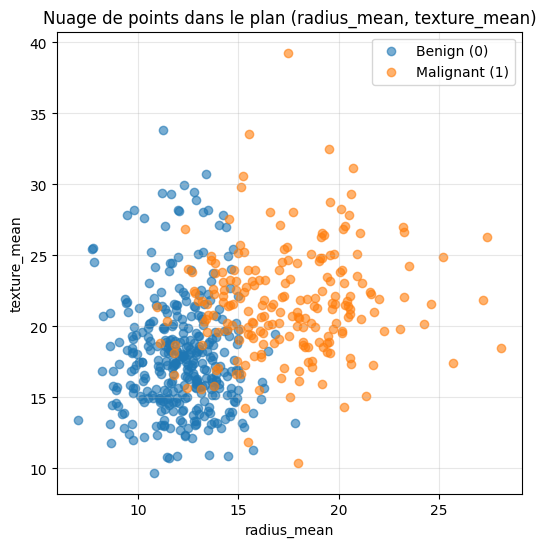

In [9]:
plt.figure(figsize=(6,6))

benign = data[data['diagnosis'] == 0]
malignant = data[data['diagnosis'] == 1]

plt.scatter(benign[feature1], benign[feature2], alpha=0.6, label='Benign (0)')
plt.scatter(malignant[feature1], malignant[feature2], alpha=0.6, label='Malignant (1)')

plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title("Nuage de points dans le plan (radius_mean, texture_mean)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 5. Normalisation des données

La normalisation min-max est appliquée à chaque feature :

$$
x_j' = \frac{x_j - \min(x_j)}{\max(x_j) - \min(x_j)}
$$

Cette étape assure une meilleure convergence du gradient descent.


In [10]:
# Normalisation min-max PAR FEATURE (colonne par colonne)
x = (x_data - x_data.min()) / (x_data.max() - x_data.min())

# Train/test split (15% test)
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.15, random_state=42, stratify=y
)

# Transposer pour avoir shape (n, m)
x_train = x_train.T   # (n_features, m_train)
x_test  = x_test.T    # (n_features, m_test)
y_train = y_train.T   # (m_train,)
y_test  = y_test.T    # (m_test,)

print("x_train :", x_train.shape)
print("x_test  :", x_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)



x_train : (30, 483)
x_test  : (30, 86)
y_train : (483,)
y_test  : (86,)


## 6. Modèle mathématique de la régression logistique

### 6.1 Hypothèse du modèle

Pour une observation \( x \in \mathbb{R}^n \), l’hypothèse est :

$$
h_\theta(x) = \sigma(\theta^T x + b)
$$

où la fonction sigmoïde est :

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

### 6.2 Interprétation probabiliste

La sortie représente :

$$
P(y=1 \mid x ; \theta)
$$

et donc :

$$
P(y=0 \mid x ; \theta) = 1 - h_\theta(x)
$$

Ainsi :

$$
y \sim \text{Bernoulli}(h_\theta(x))
$$


In [11]:
def initialize_weights_and_bias(dimension):
    """
    dimension = nombre de features n
    retourne :
    - w : vecteur colonne (n,1)
    - b : scalaire
    """
    w = np.full((dimension, 1), 0.01)
    b = 0.0
    return w, b

# Exemple d'init
dim = x_train.shape[0]
w_init, b_init = initialize_weights_and_bias(dim)
print("w_init shape :", w_init.shape)
print("b_init :", b_init)


w_init shape : (30, 1)
b_init : 0.0


In [12]:
def sigmoid(z):
    """
    Applique la fonction sigmoïde élément par élément.
    z peut être un scalaire, un vecteur ou une matrice.
    """
    return 1 / (1 + np.exp(-z))


## Forward + Backward Propagation

###  Objectif

Cette étape combine :

- **Forward propagation** : calcul de l’hypothèse et du coût  
- **Backward propagation** : calcul des gradients utilisés pour mettre à jour les paramètres

---

###  1) Forward propagation

Nous calculons d'abord la combinaison linéaire :

$$
z = w^T x + b
$$

Puis l’activation (probabilité estimée) :

$$
\hat{y} = h_\theta(x) = \sigma(z)
$$

où :

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

---

###  2) Fonction de coût (log-loss)

La fonction de coût de la régression logistique est :

$$
\displaystyle
J(\theta) = -\frac{1}{m}
\sum_{i=1}^{m}
\left[
y^{(i)} \log(\hat{y}^{(i)}) +
(1 - y^{(i)}) \log(1 - \hat{y}^{(i)})
\right]
$$

Elle dérive de la **négative log-vraisemblance** d’un modèle de Bernoulli.

---

###  3) Backward propagation (calcul des gradients)

Le gradient par rapport aux poids \( w \) est :

$$
\displaystyle
\frac{\partial J}{\partial w}
=
\frac{1}{m}
X \, (\hat{y} - y)^T
$$

Le gradient par rapport au biais \( b \) est :

$$
\displaystyle
\frac{\partial J}{\partial b}
=
\frac{1}{m}
\sum_{i=1}^{m}
\left(
\hat{y}^{(i)} - y^{(i)}
\right)
$$

---

Ces gradients seront ensuite utilisés par **gradient descent** pour mettre à jour les paramètres :

$$
w := w - \alpha \, \frac{\partial J}{\partial w},
\quad
b := b - \alpha \, \frac{\partial J}{\partial b}
$$


In [13]:
def forward_backward_propagation(w, b, x_train, y_train):
    """
    Calcule :
    - le coût J(w,b)
    - les gradients par rapport à w et b
    x_train : (n, m)
    y_train : (m,)
    """
    m = x_train.shape[1]

    # FORWARD
    z = np.dot(w.T, x_train) + b      # (1, m)
    y_head = sigmoid(z)               # (1, m)

    # Pour éviter log(0)
    eps = 1e-15
    y_head_clipped = np.clip(y_head, eps, 1 - eps)

    loss = -y_train * np.log(y_head_clipped) - (1 - y_train) * np.log(1 - y_head_clipped)
    cost = np.sum(loss) / m           # moyenne

    # BACKWARD
    # grad_w = (1/m) * X (y_head - y)^T
    derivative_weight = np.dot(x_train, (y_head - y_train).T) / m    # (n,1)
    # grad_b = (1/m) * sum(y_head - y)
    derivative_bias = np.sum(y_head - y_train) / m                  # scalaire

    gradients = {
        "derivative_weight": derivative_weight,
        "derivative_bias": derivative_bias
    }
    return cost, gradients


In [14]:
def update(w, b, x_train, y_train, learning_rate, num_iterations):
    """
    Applique gradient descent num_iterations fois.
    Retourne :
    - parameters : w, b finaux
    - gradients  : derniers gradients
    - cost_list  : historique du coût
    """
    cost_list = []
    cost_list_plot = []
    iters_plot = []

    for i in range(num_iterations):
        cost, gradients = forward_backward_propagation(w, b, x_train, y_train)
        cost_list.append(cost)

        # Mise à jour
        w = w - learning_rate * gradients["derivative_weight"]
        b = b - learning_rate * gradients["derivative_bias"]

        if i % 10 == 0:
            cost_list_plot.append(cost)
            iters_plot.append(i)
            print(f"Cost after iteration {i}: {cost:.6f}")

    # Graphique de convergence
    plt.figure(figsize=(6,4))
    plt.plot(iters_plot, cost_list_plot, marker='o')
    plt.xlabel("Iteration")
    plt.ylabel("Cost J(theta)")
    plt.title("Convergence de la fonction de coût")
    plt.grid(True)
    plt.show()

    parameters = {"weight": w, "bias": b}
    return parameters, gradients, cost_list


In [15]:
def predict(w, b, x):
    """
    Prédit les classes (0/1) pour les colonnes de x.
    x : (n, m)
    Retour : (1, m)
    """
    z = np.dot(w.T, x) + b           # (1, m)
    probs = sigmoid(z)               # (1, m)
    Y_prediction = (probs >= 0.5).astype(int)
    return Y_prediction


Cost after iteration 0: 0.692774
Cost after iteration 10: 0.497999
Cost after iteration 20: 0.405695
Cost after iteration 30: 0.351830
Cost after iteration 40: 0.316242
Cost after iteration 50: 0.290733
Cost after iteration 60: 0.271387
Cost after iteration 70: 0.256099
Cost after iteration 80: 0.243635
Cost after iteration 90: 0.233223


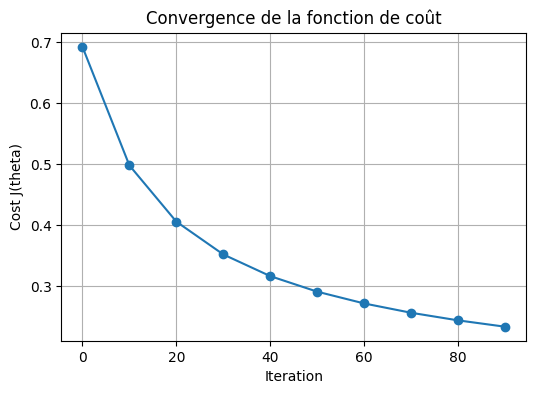

Train accuracy: 94.41 %
Test accuracy : 95.35 %


In [16]:
def logistic_regression(x_train, y_train, x_test, y_test, learning_rate, num_iterations):
    # Initialisation
    dimension = x_train.shape[0]   # n features
    w, b = initialize_weights_and_bias(dimension)

    # Entraînement (gradient descent)
    parameters, gradients, cost_list = update(w, b, x_train, y_train,
                                              learning_rate, num_iterations)

    # Prédictions
    y_pred_test = predict(parameters["weight"], parameters["bias"], x_test)
    y_pred_train = predict(parameters["weight"], parameters["bias"], x_train)

    # Accuracy
    train_acc = 100 - np.mean(np.abs(y_pred_train - y_train)) * 100
    test_acc  = 100 - np.mean(np.abs(y_pred_test - y_test)) * 100

    print(f"Train accuracy: {train_acc:.2f} %")
    print(f"Test accuracy : {test_acc:.2f} %")

    return parameters, cost_list

params, cost_list = logistic_regression(
    x_train, y_train, x_test, y_test,
    learning_rate=1.0,
    num_iterations=100
)


## Matrice de confusion (visualisation)

La matrice de confusion permet de visualiser :

- **TN** : vrais négatifs  
- **FP** : faux positifs  
- **FN** : faux négatifs  
- **TP** : vrais positifs  

Elle donne une idée qualitative des erreurs du modèle.


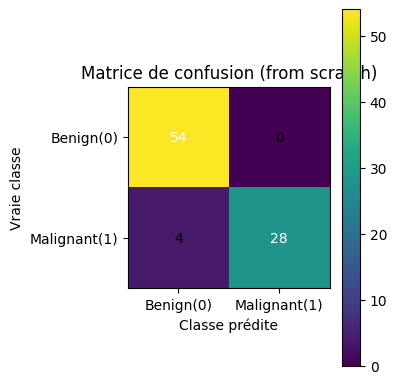

In [17]:
from sklearn.metrics import confusion_matrix

# Prédictions from scratch déjà calculées : y_pred_test
y_pred_test = predict(params["weight"], params["bias"], x_test)

cm = confusion_matrix(y_test, y_pred_test.ravel())

plt.figure(figsize=(4,4))
plt.imshow(cm, interpolation='nearest')
plt.title("Matrice de confusion (from scratch)")
plt.colorbar()
tick_marks = np.arange(2)
plt.xticks(tick_marks, ['Benign(0)', 'Malignant(1)'])
plt.yticks(tick_marks, ['Benign(0)', 'Malignant(1)'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i,j] > cm.max()/2 else "black")

plt.ylabel('Vraie classe')
plt.xlabel('Classe prédite')
plt.tight_layout()
plt.show()


##  Comparaison avec `sklearn.LogisticRegression`

Nous entraînons maintenant le modèle `LogisticRegression` de scikit-learn.
Ce modèle utilise un solveur optimisé (liblinear, lbfgs…) qui garantit une convergence efficace.

Cela nous permet de comparer :

- les performances (accuracy, AUC)
- la stabilité
- la qualité de notre implémentation *from scratch*


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

logreg = LogisticRegression(max_iter=10000, random_state=42)
logreg.fit(x_train.T, y_train.T)

y_test_pred_sklearn = logreg.predict(x_test.T)
y_train_pred_sklearn = logreg.predict(x_train.T)

print("Sklearn train accuracy :", accuracy_score(y_train, y_train_pred_sklearn))
print("Sklearn test accuracy  :", accuracy_score(y_test, y_test_pred_sklearn))

print("\nMatrice de confusion (test, sklearn) :")
print(confusion_matrix(y_test, y_test_pred_sklearn))

print("\nClassification report (test, sklearn) :")
print(classification_report(y_test, y_test_pred_sklearn, target_names=["Benign(0)", "Malignant(1)"]))


Sklearn train accuracy : 0.968944099378882
Sklearn test accuracy  : 0.9883720930232558

Matrice de confusion (test, sklearn) :
[[54  0]
 [ 1 31]]

Classification report (test, sklearn) :
              precision    recall  f1-score   support

   Benign(0)       0.98      1.00      0.99        54
Malignant(1)       1.00      0.97      0.98        32

    accuracy                           0.99        86
   macro avg       0.99      0.98      0.99        86
weighted avg       0.99      0.99      0.99        86



## Courbe ROC et AUC

La courbe ROC (Receiver Operating Characteristic) est un graphique qui illustre les performances d'un classifieur binaire. Elle trace la **True Positive Rate (TPR)** par rapport à la **False Positive Rate (FPR)** à différents seuils de discrimination.

L'**AUC (Area Under the Curve)** mesure l'aire sous la courbe ROC. Un AUC de 1.0 indique un classifieur parfait, tandis qu'un AUC de 0.5 indique un classifieur aléatoire.

/tmp/ipython-input-831512620.py:21: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([0, 1], [0, 1], 'k--', label='Random classifier (AUC = 0.50)', color='gray')


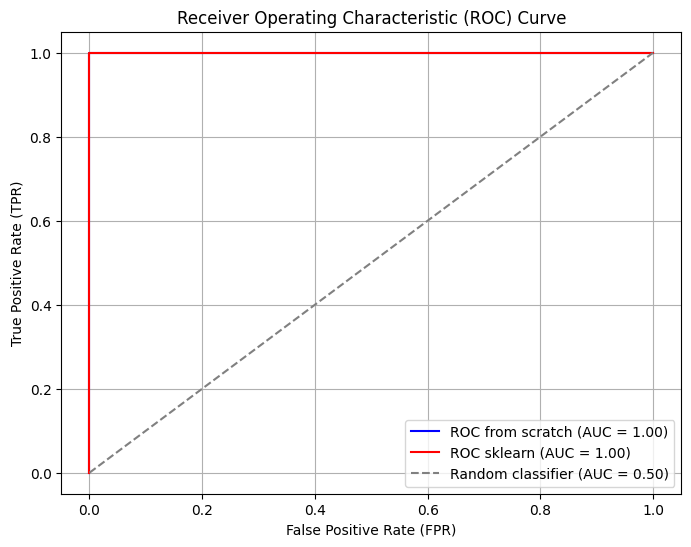

In [19]:
from sklearn.metrics import roc_curve, roc_auc_score

# Get probabilities from our 'from scratch' model
# x_test and y_test are already transposed to (n, m) and (m,) respectively
probs_from_scratch = sigmoid(np.dot(params["weight"].T, x_test) + params["bias"]).ravel()

# Calculate FPR, TPR, and thresholds for 'from scratch' model
fpr_scratch, tpr_scratch, thresholds_scratch = roc_curve(y_test, probs_from_scratch)
auc_scratch = roc_auc_score(y_test, probs_from_scratch)

# Get probabilities from sklearn model
probs_sklearn = logreg.predict_proba(x_test.T)[:, 1]

# Calculate FPR, TPR, and thresholds for sklearn model
fpr_sklearn, tpr_sklearn, thresholds_sklearn = roc_curve(y_test, probs_sklearn)
auc_sklearn = roc_auc_score(y_test, probs_sklearn)

plt.figure(figsize=(8, 6))
plt.plot(fpr_scratch, tpr_scratch, label=f'ROC from scratch (AUC = {auc_scratch:.2f})', color='blue')
plt.plot(fpr_sklearn, tpr_sklearn, label=f'ROC sklearn (AUC = {auc_sklearn:.2f})', color='red')
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier (AUC = 0.50)', color='gray')

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

## Comparaison entre la descente de gradient et la méthode de Newton

Dans ce notebook, on entraîne le **même modèle de régression logistique** avec deux méthodes d’optimisation :

- Descente de gradient (Gradient Descent, GD)
- Méthode de Newton (Newton–Raphson)

### 1. Rappel du modèle

Le modèle prédit une probabilité :

    p(w, x) = sigma(w^T x + b)

où `sigma(z)` est la fonction sigmoïde :

    sigma(z) = 1 / (1 + exp(-z))

La fonction de coût (log-loss) est :

    J(w) = -(1/m) * somme_{i=1..m} [ y_i * log(p_i) + (1 - y_i) * log(1 - p_i) ]

avec :

- `p_i = p(w, x_i)`
- `m` = nombre d’exemples

### 2. Descente de gradient (GD)

La mise à jour de GD utilise seulement le **gradient** de J(w) :

    w := w - alpha * gradient_J(w)

avec :

- `alpha` = learning rate
- `gradient_J(w) = X^T * (p - y)`

Idée : on avance petit à petit dans la direction opposée au gradient.

### 3. Méthode de Newton

La méthode de Newton utilise :

- le gradient de J(w)
- et la matrice Hessienne H (qui contient les dérivées secondes)

Formule de mise à jour :

    w := w - H^{-1} * gradient_J(w)

Dans la régression logistique, la Hessienne s’écrit :

    H = X^T * R * X

où :

- `R` est une matrice diagonale
- `R_ii = p_i * (1 - p_i)`

Idée : Newton tient compte de la **courbure** de la fonction de coût, pas seulement de la pente.



In [20]:
def logistic_regression_newton(x_train, y_train, x_test, y_test, num_iterations=10):
    """
    Version régression logistique entraînée par la méthode de Newton.
    x_train : (n_features, m_train)
    y_train : (m_train,)
    x_test  : (n_features, m_test)
    """
    # On repasse en forme (m, n)
    X_train = x_train.T   # (m_train, n)
    X_test  = x_test.T    # (m_test, n)
    m, n = X_train.shape

    # On ajoute une colonne de 1 pour le biais
    X_train_b = np.c_[np.ones((m, 1)), X_train]         # (m, n+1)
    X_test_b  = np.c_[np.ones((X_test.shape[0], 1)), X_test]  # (m_test, n+1)

    # y en colonne
    y_col = y_train.reshape(-1, 1)                      # (m, 1)

    # Initialisation de w_tilde = [b, w1, ..., wn]
    w = np.zeros((n + 1, 1))

    cost_list = []

    for it in range(num_iterations):
        # Forward
        z = X_train_b @ w           # (m, 1)
        p = sigmoid(z)              # (m, 1)

        # Pour éviter log(0)
        eps = 1e-15
        p_clip = np.clip(p, eps, 1 - eps)

        # Coût
        loss = - (y_col * np.log(p_clip) + (1 - y_col) * np.log(1 - p_clip))
        cost = loss.mean()
        cost_list.append(cost)

        # Gradient : (n+1, 1)
        grad = X_train_b.T @ (p - y_col) / m

        # Hessienne : H = X^T R X, avec R diagonale
        r = (p * (1 - p)).flatten()          # (m,)
        R = np.diag(r)                       # (m, m)
        H = X_train_b.T @ R @ X_train_b / m  # (n+1, n+1)

        # Mise à jour de Newton
        w = w - np.linalg.inv(H) @ grad

        print(f"[Newton] Iteration {it}, cost = {cost:.6f}")

    # Prédictions train
    z_train = X_train_b @ w
    p_train = sigmoid(z_train)
    y_pred_train = (p_train >= 0.5).astype(int).flatten()

    # Prédictions test
    z_test = X_test_b @ w
    p_test = sigmoid(z_test)
    y_pred_test = (p_test >= 0.5).astype(int).flatten()

    # Accuracy
    train_acc = 100 - np.mean(np.abs(y_pred_train - y_train)) * 100
    test_acc  = 100 - np.mean(np.abs(y_pred_test  - y_test))  * 100

    print(f"[Newton] Train accuracy: {train_acc:.2f} %")
    print(f"[Newton] Test accuracy : {test_acc:.2f} %")

    # On retourne w_tilde et la liste de coûts
    return w, cost_list


Cost after iteration 0: 0.692774
Cost after iteration 10: 0.497999
Cost after iteration 20: 0.405695
Cost after iteration 30: 0.351830
Cost after iteration 40: 0.316242
Cost after iteration 50: 0.290733
Cost after iteration 60: 0.271387
Cost after iteration 70: 0.256099
Cost after iteration 80: 0.243635
Cost after iteration 90: 0.233223


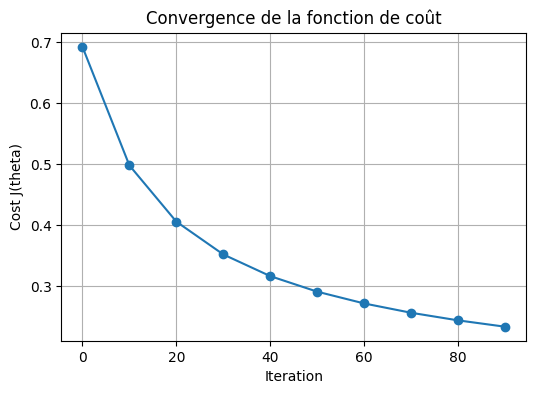

Train accuracy: 94.41 %
Test accuracy : 95.35 %
[Newton] Iteration 0, cost = 0.693147
[Newton] Iteration 1, cost = 0.235914
[Newton] Iteration 2, cost = 0.135969
[Newton] Iteration 3, cost = 0.088495
[Newton] Iteration 4, cost = 0.063417
[Newton] Train accuracy: 98.55 %
[Newton] Test accuracy : 97.67 %


In [21]:

def logistic_regression(x_train, y_train, x_test, y_test, learning_rate, num_iterations):
    # Initialisation
    dimension = x_train.shape[0]   # n features
    w, b = initialize_weights_and_bias(dimension)

    # Entraînement (gradient descent)
    parameters, gradients, cost_list = update(w, b, x_train, y_train,
                                              learning_rate, num_iterations)

    # Prédictions
    y_pred_test = predict(parameters["weight"], parameters["bias"], x_test)
    y_pred_train = predict(parameters["weight"], parameters["bias"], x_train)

    # Accuracy
    train_acc = 100 - np.mean(np.abs(y_pred_train - y_train)) * 100
    test_acc  = 100 - np.mean(np.abs(y_pred_test - y_test)) * 100

    print(f"Train accuracy: {train_acc:.2f} %")
    print(f"Test accuracy : {test_acc:.2f} %")

    return parameters, cost_list

params, cost_list = logistic_regression(
    x_train, y_train, x_test, y_test,
    learning_rate=1.0,
    num_iterations=100
)


# ---- Entraînement avec la Méthode de Newton ----
w_newton, cost_list_newton = logistic_regression_newton(
    x_train, y_train, x_test, y_test,
    num_iterations=5      # Newton converge vite, 5 à 10 itérations suffisent
)


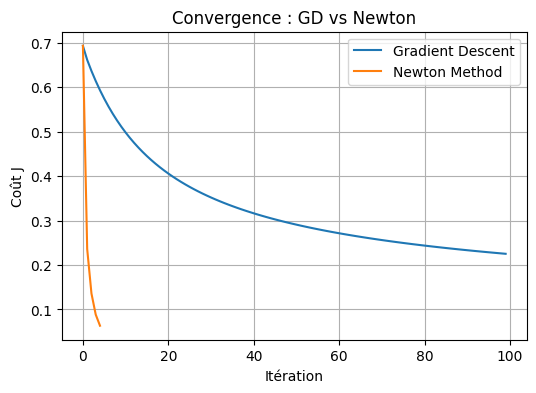

In [23]:
plt.figure(figsize=(6,4))
plt.plot(cost_list, label="Gradient Descent")
plt.plot(cost_list_newton, label="Newton Method")
plt.xlabel("Itération")
plt.ylabel("Coût J")
plt.title("Convergence : GD vs Newton")
plt.legend()
plt.grid(True)
plt.show()

### 4. Ce qu’on observe dans les résultats

- Avec la descente de gradient :
  - le coût J(w) diminue progressivement au fil des itérations
  - il faut beaucoup d’itérations, mais chaque itération est peu coûteuse

- Avec la méthode de Newton :
  - le coût J(w) chute très vite en quelques itérations seulement
  - chaque itération est plus coûteuse (calcul + inversion de H)

Comme la fonction de coût de la régression logistique est **convexe**, les deux méthodes convergent vers le **même minimum global** (mêmes paramètres optimaux w, mêmes performances : accuracy, AUC, etc.).

### 5. Résumé

- Descente de gradient :
  - simple, scalable
  - nécessite un learning rate
  - beaucoup d’itérations

- Méthode de Newton :
  - plus avancée, utilise la Hessienne
  - pas de learning rate à choisir
  - très peu d’itérations, mais chaque itération est lourde

Dans ce projet, comparer GD et Newton montre que :
- notre modèle est correct
- nous savons utiliser deux méthodes d’optimisation différentes sur la même régression logistique.


#  Conclusion

Dans ce notebook, nous avons :

- exploré les données et visualisé les distributions  
- formulé mathématiquement la régression logistique  
- dérivé la fonction de coût et le gradient  
- implémenté le modèle en NumPy (*from scratch*)  
- utilisé la descente de gradient pour apprendre les paramètres  
- évalué le modèle avec plusieurs métriques  
- comparé avec l'implémentation scikit-learn  

Ce travail montre le lien entre :

- théorie mathématique  
- optimisation (gradient descentet La méthode de Newton (aussi appelée Newton-Raphson))  
- implémentation pratique en Python  
- évaluation et diagnostics  

**Objectif atteint : comprendre le modèle du début à la fin.**
